# Problem 4: The Attention Surgery Experiment

This notebook studies **which ViT attention heads matter most** for your crowd-density dataset. We fine-tune a pretrained ViT on the `low`, `medium`, and `high` crowd classes, then ablate one attention head at a time by forcing that head to use a **uniform attention distribution**.

To make the assignment measurable on this dataset, we use three controlled probes:
- **Texture recognition**: deterministic patch shuffling preserves local texture while disrupting global structure.
- **Shape recognition**: an edge-based view suppresses texture and keeps coarse shape boundaries.
- **Spatial localization**: a quadrant-alignment score compares occlusion sensitivity against an automatically estimated crowd-heavy image quadrant.

The deliverables are: a **head importance map**, metric tables, and **example images where specific heads matter**.


> **Setup.** This notebook expects the crowd-density images at `data/data/{high_new1,low_new1,medium_new1}/` (see [`DATA.md`](../DATA.md)). The dataset is **not** included in this repository. The original `!unzip data.zip -d data` cell is kept for Colab use; skip it if the folders are already in place.
>
> **Probe definitions (as implemented).** *Texture* probe = deterministic patch shuffle (reversing the order of 16 px patches inside 2x2 blocks); *shape* probe = binary edge map; *spatial* probe = occlusion-sensitivity quadrant compared with an edge-density heuristic. The head sweep runs on a 45-image probe subset (15 per class), so single-head effects of a few points are within noise.

In [87]:
!unzip data.zip -d data

In [88]:
!pip install -q transformers seaborn

In [89]:
import copy
import json
import math
import os
import random
import time
import types
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image, ImageFilter, ImageOps
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
from transformers import AutoImageProcessor, ViTForImageClassification

sns.set_theme(style='whitegrid')


## Configuration

These defaults are conservative enough for Colab Free Tier. The `HEAD_SCAN_PER_CLASS` and `LOCALIZATION_SAMPLES` settings are the main levers that trade accuracy of the analysis against runtime.


In [90]:
SEED = 42
DATA_ROOT = Path('data/data')
MODEL_NAME = 'google/vit-base-patch16-224'
IMAGE_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 5
LR = 2e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0
HEAD_SCAN_PER_CLASS = 15
LOCALIZATION_SAMPLES = 24
LOCALIZATION_GRID = 4
EXAMPLES_PER_CATEGORY = 4
CLASS_NAMES = ['low', 'medium', 'high']
QUADRANT_NAMES = ['top_left', 'top_right', 'bottom_left', 'bottom_right']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print(f'Using device: {DEVICE}')


Using device: cuda


## Dataset And Probes

The dataset is the same crowd-density dataset used in `problem14`. We infer the semantic class labels from folder names, then create three deterministic diagnostic views:
- `clean`: original image
- `texture`: local texture preserved, global structure disrupted
- `shape`: edge map that removes most texture detail


In [91]:
def infer_class_from_folder(folder_name):
    name = folder_name.lower()
    if 'low' in name:
        return 'low'
    if 'medium' in name or 'mid' in name:
        return 'medium'
    if 'high' in name:
        return 'high'
    raise ValueError(f'Could not infer class from folder name: {folder_name}')


def load_rgb_image(path):
    with Image.open(path) as image:
        return image.convert('RGB')


def is_valid_image(path):
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except Exception as exc:
        print(f'Skipping unreadable image: {path} ({exc})')
        return False


def build_folder_remap(class_to_idx):
    remap = {}
    for folder_name, folder_idx in class_to_idx.items():
        class_name = infer_class_from_folder(folder_name)
        remap[folder_idx] = CLASS_NAMES.index(class_name)
    return remap


def deterministic_patch_shuffle(image, patch_size=16, block_size=2):
    image = image.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    arr = np.array(image)
    out = arr.copy()
    block_px = patch_size * block_size
    reverse_order = list(range(block_size * block_size))[::-1]

    for y in range(0, IMAGE_SIZE, block_px):
        for x in range(0, IMAGE_SIZE, block_px):
            patches = []
            coords = []
            for by in range(block_size):
                for bx in range(block_size):
                    yy = y + by * patch_size
                    xx = x + bx * patch_size
                    if yy + patch_size <= IMAGE_SIZE and xx + patch_size <= IMAGE_SIZE:
                        patches.append(arr[yy:yy + patch_size, xx:xx + patch_size].copy())
                        coords.append((yy, xx))
            if len(patches) == len(reverse_order):
                for dst_idx, src_idx in enumerate(reverse_order):
                    yy, xx = coords[dst_idx]
                    out[yy:yy + patch_size, xx:xx + patch_size] = patches[src_idx]

    return Image.fromarray(out)


def edge_shape_view(image):
    image = image.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    gray = ImageOps.grayscale(image)
    smooth = gray.filter(ImageFilter.GaussianBlur(radius=1.2))
    edges = smooth.filter(ImageFilter.FIND_EDGES)
    edges = ImageOps.autocontrast(edges)
    edges = edges.point(lambda p: 255 if p > 32 else 0)
    return Image.merge('RGB', (edges, edges, edges))


VIEW_TRANSFORMS = {
    'clean': lambda image: image.convert('RGB'),
    'texture': deterministic_patch_shuffle,
    'shape': edge_shape_view,
}


def estimate_crowd_quadrant(image):
    image = image.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    gray = ImageOps.grayscale(image)
    smooth = gray.filter(ImageFilter.GaussianBlur(radius=1.0))
    edges = smooth.filter(ImageFilter.FIND_EDGES)
    saliency = np.asarray(ImageOps.autocontrast(edges), dtype=np.float32)
    half_h = saliency.shape[0] // 2
    half_w = saliency.shape[1] // 2
    quadrant_sums = [
        saliency[:half_h, :half_w].sum(),
        saliency[:half_h, half_w:].sum(),
        saliency[half_h:, :half_w].sum(),
        saliency[half_h:, half_w:].sum(),
    ]
    return int(np.argmax(quadrant_sums))


class CrowdVitDataset(Dataset):
    def __init__(self, base_dataset, indices, processor, folder_remap, view='clean'):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.processor = processor
        self.folder_remap = folder_remap
        self.view = view

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        while True:
            sample_idx = self.indices[idx]
            path, label = self.base_dataset.samples[sample_idx]
            try:
                image = load_rgb_image(path)
                transformed = VIEW_TRANSFORMS[self.view](image)
                pixel_values = self.processor(images=transformed, return_tensors='pt')['pixel_values'][0]
                return {
                    'pixel_values': pixel_values,
                    'labels': self.folder_remap[label],
                    'path': path,
                    'sample_idx': sample_idx,
                    'view': self.view,
                }
            except Exception as exc:
                print(f'Skipping unreadable image during dataset fetch: {path} ({exc})')
                idx = (idx + 1) % len(self.indices)


def collate_batch(batch):
    return {
        'pixel_values': torch.stack([item['pixel_values'] for item in batch]),
        'labels': torch.tensor([item['labels'] for item in batch], dtype=torch.long),
        'paths': [item['path'] for item in batch],
        'sample_idx': [item['sample_idx'] for item in batch],
        'view': [item['view'] for item in batch],
    }


def filter_valid_indices(base_dataset, indices):
    valid_indices = []
    skipped_paths = []
    for idx in indices:
        path, _ = base_dataset.samples[idx]
        if is_valid_image(path):
            valid_indices.append(idx)
        else:
            skipped_paths.append(path)
    return valid_indices, skipped_paths


def make_splits(data_root):
    base_dataset = ImageFolder(root=str(data_root))
    folder_remap = build_folder_remap(base_dataset.class_to_idx)
    labels = [folder_remap[label] for _, label in base_dataset.samples]
    idx_all = np.arange(len(base_dataset))

    idx_trainval, idx_test = train_test_split(
        idx_all,
        test_size=0.15,
        stratify=labels,
        random_state=SEED,
    )

    labels_tv = [labels[i] for i in idx_trainval]
    idx_train, idx_val = train_test_split(
        idx_trainval,
        test_size=0.176,
        stratify=labels_tv,
        random_state=SEED,
    )

    idx_train, skipped_train = filter_valid_indices(base_dataset, list(idx_train))
    idx_val, skipped_val = filter_valid_indices(base_dataset, list(idx_val))
    idx_test, skipped_test = filter_valid_indices(base_dataset, list(idx_test))

    skipped = {
        'train': skipped_train,
        'val': skipped_val,
        'test': skipped_test,
    }
    return base_dataset, folder_remap, labels, idx_train, idx_val, idx_test, skipped


def balanced_subset_indices(indices, labels, per_class):
    grouped = defaultdict(list)
    for idx in indices:
        grouped[labels[idx]].append(idx)

    rng = random.Random(SEED)
    selected = []
    for class_id in sorted(grouped):
        candidates = grouped[class_id][:]
        rng.shuffle(candidates)
        selected.extend(candidates[: min(per_class, len(candidates))])
    return selected


def make_loader(base_dataset, indices, processor, folder_remap, view='clean', shuffle=False):
    dataset = CrowdVitDataset(base_dataset, indices, processor, folder_remap, view=view)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        collate_fn=collate_batch,
    )


## Model And Attention Surgery

We use a pretrained ViT and replace the classifier head for the three crowd classes. Attention surgery is implemented by monkey-patching each self-attention layer so that selected heads are forced to attend uniformly across tokens.


In [92]:
def build_model(num_labels):
    processor = AutoImageProcessor.from_pretrained(MODEL_NAME, use_fast=True)
    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=num_labels,
        attn_implementation='eager',
        ignore_mismatched_sizes=True,
        id2label={i: name for i, name in enumerate(CLASS_NAMES)},
        label2id={name: i for i, name in enumerate(CLASS_NAMES)},
    )
    return model.to(DEVICE), processor


class ViTHeadAblator:
    def __init__(self, model):
        self.model = model
        self.layers = [layer.attention.attention for layer in model.vit.encoder.layer]
        self.original_forwards = []
        self.ablation_map = {}

        for layer_idx, module in enumerate(self.layers):
            self.original_forwards.append(module.forward)
            module.forward = types.MethodType(self._make_forward(layer_idx), module)

    def _make_forward(self, layer_idx):
        def patched_forward(module, hidden_states, head_mask=None, output_attentions=False, **kwargs):
            def reshape_for_scores(x):
                new_x_shape = x.size()[:-1] + (module.num_attention_heads, module.attention_head_size)
                x = x.view(*new_x_shape)
                return x.permute(0, 2, 1, 3)

            mixed_query_layer = module.query(hidden_states)
            key_layer = reshape_for_scores(module.key(hidden_states))
            value_layer = reshape_for_scores(module.value(hidden_states))
            query_layer = reshape_for_scores(mixed_query_layer)

            attention_scores = torch.matmul(query_layer, key_layer.transpose(-1, -2))
            attention_scores = attention_scores / math.sqrt(module.attention_head_size)
            attention_probs = torch.softmax(attention_scores, dim=-1)

            if layer_idx in self.ablation_map:
                head_ids = self.ablation_map[layer_idx]
                uniform = torch.full(
                    (attention_probs.size(0), len(head_ids), attention_probs.size(2), attention_probs.size(3)),
                    1.0 / attention_probs.size(-1),
                    dtype=attention_probs.dtype,
                    device=attention_probs.device,
                )
                attention_probs[:, head_ids, :, :] = uniform

            if hasattr(module, 'dropout'):
                attention_probs = module.dropout(attention_probs)
            else:
                dropout_p = 0.0
                if hasattr(module, 'attention_dropout'):
                    dropout_value = module.attention_dropout
                    dropout_p = dropout_value.p if hasattr(dropout_value, 'p') else float(dropout_value)
                elif hasattr(module, 'attention_probs_dropout_prob'):
                    dropout_p = float(module.attention_probs_dropout_prob)
                attention_probs = torch.nn.functional.dropout(attention_probs, p=dropout_p, training=module.training)
            if head_mask is not None:
                attention_probs = attention_probs * head_mask

            context_layer = torch.matmul(attention_probs, value_layer)
            context_layer = context_layer.permute(0, 2, 1, 3).contiguous()
            new_context_shape = context_layer.size()[:-2] + (module.all_head_size,)
            context_layer = context_layer.view(new_context_shape)

            attn_weights = attention_probs if output_attentions else None
            return context_layer, attn_weights

        return patched_forward

    def set_single_head(self, layer_idx, head_idx):
        self.ablation_map = {int(layer_idx): [int(head_idx)]}

    def clear(self):
        self.ablation_map = {}

    def restore(self):
        for module, forward in zip(self.layers, self.original_forwards):
            module.forward = forward


## Training, Evaluation, And Diagnostics

The baseline evaluation reports standard classification metrics on clean images, then repeats them on the texture and shape probes. The spatial localization metric is a **quadrant alignment score**: if the most important occluded region falls in the same quadrant as the estimated crowd-heavy quadrant, the prediction is counted as spatially aligned.


In [93]:
def class_weights_from_indices(indices, labels):
    counts = np.bincount([labels[idx] for idx in indices], minlength=len(CLASS_NAMES))
    counts[counts == 0] = 1
    weights = torch.tensor(1.0 / counts, dtype=torch.float32, device=DEVICE)
    return weights


def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    preds, labels = [], []

    for batch in loader:
        pixel_values = batch['pixel_values'].to(DEVICE)
        targets = batch['labels'].to(DEVICE)

        optimizer.zero_grad()
        outputs = model(pixel_values=pixel_values)
        loss = criterion(outputs.logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.size(0)
        preds.extend(outputs.logits.argmax(dim=1).detach().cpu().tolist())
        labels.extend(targets.detach().cpu().tolist())

    return {
        'loss': running_loss / len(loader.dataset),
        'acc': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
    }


@torch.no_grad()
def evaluate_loader(model, loader, criterion=None):
    model.eval()
    losses = []
    preds, labels, probs, paths = [], [], [], []

    for batch in loader:
        pixel_values = batch['pixel_values'].to(DEVICE)
        targets = batch['labels'].to(DEVICE)

        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits

        if criterion is not None:
            losses.append(criterion(logits, targets).item() * targets.size(0))

        batch_probs = torch.softmax(logits, dim=1)
        preds.extend(logits.argmax(dim=1).cpu().tolist())
        labels.extend(targets.cpu().tolist())
        probs.extend(batch_probs.cpu().tolist())
        paths.extend(batch['paths'])

    metrics = {
        'acc': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'labels': labels,
        'preds': preds,
        'probs': probs,
        'paths': paths,
        'report': classification_report(
            labels, preds, target_names=CLASS_NAMES, zero_division=0, output_dict=True
        ),
    }

    if criterion is not None:
        metrics['loss'] = sum(losses) / len(loader.dataset)

    return metrics


def fit_model(model, train_loader, val_loader, train_indices, labels):
    weights = class_weights_from_indices(train_indices, labels)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_val = -1.0
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(EPOCHS):
        train_metrics = train_epoch(model, train_loader, optimizer, criterion)
        val_metrics = evaluate_loader(model, val_loader, criterion=criterion)
        history.append({
            'epoch': epoch + 1,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_macro_f1': val_metrics['macro_f1'],
        })

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"train_acc={train_metrics['acc']:.4f} | val_acc={val_metrics['acc']:.4f} | "
            f"train_f1={train_metrics['macro_f1']:.4f} | val_f1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics['acc'] > best_val:
            best_val = val_metrics['acc']
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return pd.DataFrame(history), criterion


def plot_training_history(history_df):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df['epoch'], history_df['train_acc'], marker='o', label='train_acc')
    axes[0].plot(history_df['epoch'], history_df['val_acc'], marker='o', label='val_acc')
    axes[0].set_title('Accuracy')
    axes[0].legend()

    axes[1].plot(history_df['epoch'], history_df['train_macro_f1'], marker='o', label='train_macro_f1')
    axes[1].plot(history_df['epoch'], history_df['val_macro_f1'], marker='o', label='val_macro_f1')
    axes[1].set_title('Macro F1')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_confusion(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()


def cell_quadrant(row, col, grid_size=LOCALIZATION_GRID):
    top = row < (grid_size // 2)
    left = col < (grid_size // 2)
    if top and left:
        return 0
    if top and not left:
        return 1
    if not top and left:
        return 2
    return 3


@torch.no_grad()
def quadrant_localization_score(model, dataset, max_samples=LOCALIZATION_SAMPLES, only_correct=True):
    model.eval()
    rows = []

    for sample_pos in range(min(len(dataset), max_samples)):
        sample = dataset[sample_pos]
        pixel_values = sample['pixel_values'].unsqueeze(0).to(DEVICE)
        label = int(sample['labels'])

        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits[0]
        pred = int(logits.argmax().item())
        if only_correct and pred != label:
            continue

        base_true_logit = float(logits[label].item())
        patch_scores = np.zeros((LOCALIZATION_GRID, LOCALIZATION_GRID), dtype=np.float32)
        h = pixel_values.shape[-2]
        w = pixel_values.shape[-1]
        cell_h = h // LOCALIZATION_GRID
        cell_w = w // LOCALIZATION_GRID

        for row in range(LOCALIZATION_GRID):
            for col in range(LOCALIZATION_GRID):
                occluded = pixel_values.clone()
                y0 = row * cell_h
                y1 = h if row == LOCALIZATION_GRID - 1 else (row + 1) * cell_h
                x0 = col * cell_w
                x1 = w if col == LOCALIZATION_GRID - 1 else (col + 1) * cell_w
                occluded[:, :, y0:y1, x0:x1] = 0.0
                occluded_logits = model(pixel_values=occluded).logits[0]
                patch_scores[row, col] = base_true_logit - float(occluded_logits[label].item())

        best_cell = np.unravel_index(np.argmax(patch_scores), patch_scores.shape)
        predicted_quadrant = cell_quadrant(best_cell[0], best_cell[1])
        target_quadrant = estimate_crowd_quadrant(load_rgb_image(sample['path']))

        rows.append({
            'path': sample['path'],
            'label': label,
            'pred': pred,
            'target_quadrant': target_quadrant,
            'predicted_quadrant': predicted_quadrant,
            'match': int(predicted_quadrant == target_quadrant),
            'peak_drop': float(patch_scores.max()),
        })

    score = float(np.mean([row['match'] for row in rows])) if rows else float('nan')
    return score, pd.DataFrame(rows)


## Head Importance Sweep

For each head, we compute the metric drop after ablating that head alone. The largest drops identify heads that are most critical for each diagnostic capability.


In [94]:
def evaluate_metric_bundle(model, clean_loader, texture_loader, shape_loader, localization_dataset):
    clean_metrics = evaluate_loader(model, clean_loader)
    texture_metrics = evaluate_loader(model, texture_loader)
    shape_metrics = evaluate_loader(model, shape_loader)
    spatial_score, spatial_details = quadrant_localization_score(model, localization_dataset)

    bundle = {
        'clean_acc': clean_metrics['acc'],
        'clean_macro_f1': clean_metrics['macro_f1'],
        'texture_acc': texture_metrics['acc'],
        'texture_macro_f1': texture_metrics['macro_f1'],
        'shape_acc': shape_metrics['acc'],
        'shape_macro_f1': shape_metrics['macro_f1'],
        'spatial_alignment': spatial_score,
        'clean_metrics': clean_metrics,
        'texture_metrics': texture_metrics,
        'shape_metrics': shape_metrics,
        'spatial_details': spatial_details,
    }
    return bundle


def run_head_ablation_sweep(model, ablator, probe_loaders, localization_dataset):
    baseline = evaluate_metric_bundle(
        model,
        probe_loaders['clean'],
        probe_loaders['texture'],
        probe_loaders['shape'],
        localization_dataset,
    )

    num_layers = model.config.num_hidden_layers
    num_heads = model.config.num_attention_heads
    rows = []

    for layer_idx in range(num_layers):
        for head_idx in range(num_heads):
            ablator.set_single_head(layer_idx, head_idx)
            ablated = evaluate_metric_bundle(
                model,
                probe_loaders['clean'],
                probe_loaders['texture'],
                probe_loaders['shape'],
                localization_dataset,
            )
            ablator.clear()

            rows.append({
                'layer': layer_idx,
                'head': head_idx,
                'clean_acc_drop': baseline['clean_acc'] - ablated['clean_acc'],
                'texture_acc_drop': baseline['texture_acc'] - ablated['texture_acc'],
                'shape_acc_drop': baseline['shape_acc'] - ablated['shape_acc'],
                'spatial_drop': baseline['spatial_alignment'] - ablated['spatial_alignment'],
                'clean_macro_f1_drop': baseline['clean_macro_f1'] - ablated['clean_macro_f1'],
                'texture_macro_f1_drop': baseline['texture_macro_f1'] - ablated['texture_macro_f1'],
                'shape_macro_f1_drop': baseline['shape_macro_f1'] - ablated['shape_macro_f1'],
                'baseline_clean_acc': baseline['clean_acc'],
                'baseline_texture_acc': baseline['texture_acc'],
                'baseline_shape_acc': baseline['shape_acc'],
                'baseline_spatial_alignment': baseline['spatial_alignment'],
            })

            print(
                f'Layer {layer_idx:02d} Head {head_idx:02d} | '
                f'texture_drop={rows[-1]["texture_acc_drop"]:.4f} | '
                f'shape_drop={rows[-1]["shape_acc_drop"]:.4f} | '
                f'spatial_drop={rows[-1]["spatial_drop"]:.4f}'
            )

    return pd.DataFrame(rows), baseline


def plot_head_heatmap(head_df, column, title):
    pivot = head_df.pivot(index='layer', columns='head', values=column)
    plt.figure(figsize=(12, 6))
    sns.heatmap(pivot, cmap='magma', center=0.0)
    plt.title(title)
    plt.xlabel('Head')
    plt.ylabel('Layer')
    plt.tight_layout()
    plt.show()
    return pivot


@torch.no_grad()
def collect_probability_drop_examples(model, ablator, dataset, layer_idx, head_idx, top_k=EXAMPLES_PER_CATEGORY):
    rows = []
    ablator.clear()

    for pos in range(len(dataset)):
        sample = dataset[pos]
        pixel_values = sample['pixel_values'].unsqueeze(0).to(DEVICE)
        label = int(sample['labels'])

        base_probs = torch.softmax(model(pixel_values=pixel_values).logits[0], dim=0)
        base_true = float(base_probs[label].item())

        ablator.set_single_head(layer_idx, head_idx)
        ablated_probs = torch.softmax(model(pixel_values=pixel_values).logits[0], dim=0)
        ablator.clear()
        ablated_true = float(ablated_probs[label].item())

        rows.append({
            'path': sample['path'],
            'label': label,
            'base_true_prob': base_true,
            'ablated_true_prob': ablated_true,
            'prob_drop': base_true - ablated_true,
        })

    df = pd.DataFrame(rows).sort_values('prob_drop', ascending=False).head(top_k).reset_index(drop=True)
    return df


@torch.no_grad()
def collect_spatial_examples(model, ablator, dataset, layer_idx, head_idx, top_k=EXAMPLES_PER_CATEGORY):
    ablator.clear()
    base_score, base_details = quadrant_localization_score(model, dataset, max_samples=min(len(dataset), LOCALIZATION_SAMPLES), only_correct=True)
    ablator.set_single_head(layer_idx, head_idx)
    ablated_score, ablated_details = quadrant_localization_score(model, dataset, max_samples=min(len(dataset), LOCALIZATION_SAMPLES), only_correct=True)
    ablator.clear()

    merged = base_details.merge(
        ablated_details,
        on='path',
        how='inner',
        suffixes=('_base', '_ablated'),
    )
    if merged.empty:
        return pd.DataFrame(), base_score, ablated_score

    merged['match_drop'] = merged['match_base'] - merged['match_ablated']
    merged['peak_drop_change'] = merged['peak_drop_base'] - merged['peak_drop_ablated']
    merged = merged.sort_values(['match_drop', 'peak_drop_change'], ascending=False).head(top_k).reset_index(drop=True)
    return merged, base_score, ablated_score


def show_image_examples(example_df, title, view='clean'):
    if example_df.empty:
        print(f'No examples available for {title}.')
        return

    cols = min(len(example_df), 4)
    fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 4))
    if cols == 1:
        axes = [axes]

    for ax, row in zip(axes, example_df.to_dict('records')):
        image = load_rgb_image(row['path'])
        image = VIEW_TRANSFORMS[view](image)
        ax.imshow(image)
        ax.axis('off')
        label_value = row.get('label', row.get('label_base', row.get('label_ablated')))
        summary = []
        if label_value is not None and not pd.isna(label_value):
            summary.append(f"label={CLASS_NAMES[int(label_value)]}")
        if 'prob_drop' in row and not pd.isna(row['prob_drop']):
            summary.append(f"drop={row['prob_drop']:.3f}")
        if 'match_drop' in row and not pd.isna(row['match_drop']):
            summary.append(f"match_drop={row['match_drop']:.1f}")
        if 'target_quadrant_base' in row and not pd.isna(row['target_quadrant_base']):
            summary.append(f"target_q={QUADRANT_NAMES[int(row['target_quadrant_base'])]}")
        ax.set_title('\n'.join(summary) if summary else title)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


## Run The Experiment

This final block fine-tunes the ViT, evaluates the three probes, runs the head-ablation sweep on a balanced test subset, and displays all tables, heatmaps, examples, and summaries directly in the notebook.


Skipping unreadable image: data/data/high_new1/1894_2.png (cannot identify image file 'data/data/high_new1/1894_2.png')
Dataset folders: {'high_new1': 0, 'low_new1': 1, 'medium_new1': 2}
Train / Val / Test: 1332 285 285
Skipped unreadable files: {'train': 0, 'val': 0, 'test': 1}


ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch 1/5 | train_acc=0.8514 | val_acc=0.9158 | train_f1=0.8439 | val_f1=0.9120
Epoch 2/5 | train_acc=0.9805 | val_acc=0.9263 | train_f1=0.9796 | val_f1=0.9244
Epoch 3/5 | train_acc=0.9992 | val_acc=0.9263 | train_f1=0.9991 | val_f1=0.9222
Epoch 4/5 | train_acc=1.0000 | val_acc=0.9333 | train_f1=1.0000 | val_f1=0.9296
Epoch 5/5 | train_acc=1.0000 | val_acc=0.9333 | train_f1=1.0000 | val_f1=0.9296


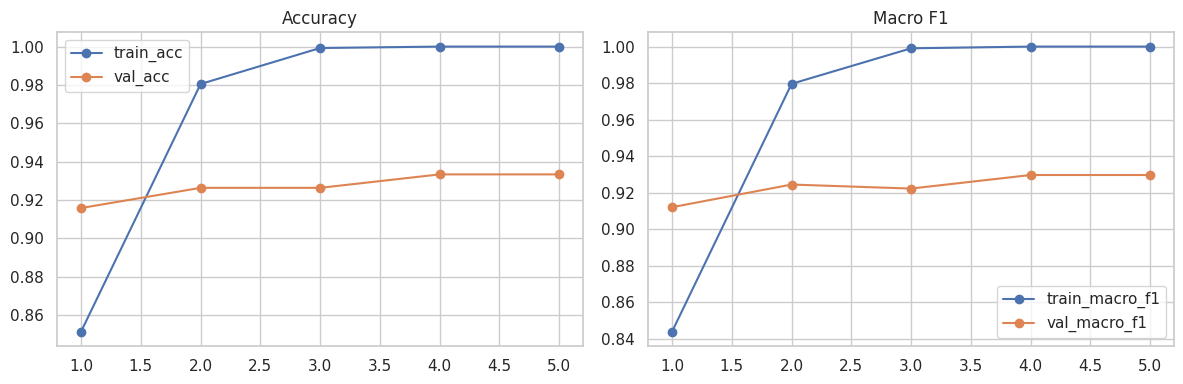

,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1
0,1,0.4136,0.8514,0.8439,0.2438,0.9158,0.9120
1,2,0.0779,0.9805,0.9796,0.1764,0.9263,0.9244
2,3,0.0164,0.9992,0.9991,0.1742,0.9263,0.9222
3,4,0.0046,1.0000,1.0000,0.1921,0.9333,0.9296
4,5,0.0026,1.0000,1.0000,0.2058,0.9333,0.9296


,view,accuracy,macro_f1
0,clean,0.950877,0.949566
1,texture,0.926316,0.928442
2,shape,0.445614,0.339063
3,spatial_alignment,0.458333,NaN


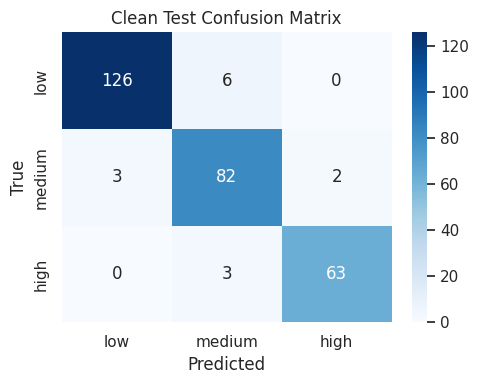

Clean-view classification report


,precision,recall,f1-score,support
low,0.9767,0.9545,0.9655,132.0000
medium,0.9011,0.9425,0.9213,87.0000
high,0.9692,0.9545,0.9618,66.0000
accuracy,0.9509,0.9509,0.9509,0.9509
macro avg,0.9490,0.9505,0.9496,285.0000
weighted avg,0.9519,0.9509,0.9512,285.0000


Texture-probe classification report


,precision,recall,f1-score,support
low,0.9754,0.9015,0.9370,132.0000
medium,0.8367,0.9425,0.8865,87.0000
high,0.9692,0.9545,0.9618,66.0000
accuracy,0.9263,0.9263,0.9263,0.9263
macro avg,0.9271,0.9329,0.9284,285.0000
weighted avg,0.9316,0.9263,0.9273,285.0000


Shape-probe classification report


,precision,recall,f1-score,support
low,0.7125,0.4318,0.5377,132.0000
medium,0.3415,0.8046,0.4795,87.0000
high,0.0000,0.0000,0.0000,66.0000
accuracy,0.4456,0.4456,0.4456,0.4456
macro avg,0.3513,0.4121,0.3391,285.0000
weighted avg,0.4342,0.4456,0.3954,285.0000


Spatial localization details


,path,label,pred,target_quadrant,predicted_quadrant,match,peak_drop
0,data/data/low_new1/406_0.jpg,0,0,2,2,1,0.326711
1,data/data/high_new1/1718_2.jpg,2,2,3,3,1,2.615331
2,data/data/medium_new1/1227_1.jpg,1,1,3,3,1,0.728216
3,data/data/medium_new1/1024_1.jpg,1,1,1,0,0,1.413904
4,data/data/high_new1/1685_2.jpg,2,2,1,3,0,0.152965
5,data/data/medium_new1/1424_1.png,1,1,3,3,1,0.432805
6,data/data/low_new1/799_0.jpg,0,0,0,2,0,0.782804
7,data/data/high_new1/1803_2.jpg,2,2,0,2,0,0.329113
8,data/data/high_new1/1839_2.jpg,2,2,0,2,0,0.440201
9,data/data/low_new1/730_0.jpg,0,0,2,1,0,0.367801


Layer 00 Head 00 | texture_drop=0.0667 | shape_drop=-0.0222 | spatial_drop=0.0000
Layer 00 Head 01 | texture_drop=0.0889 | shape_drop=0.0222 | spatial_drop=0.1364
Layer 00 Head 02 | texture_drop=0.0000 | shape_drop=-0.0222 | spatial_drop=-0.1082
Layer 00 Head 03 | texture_drop=0.0222 | shape_drop=0.0000 | spatial_drop=0.0000
Layer 00 Head 04 | texture_drop=0.2222 | shape_drop=-0.0444 | spatial_drop=-0.0189
Layer 00 Head 05 | texture_drop=0.0444 | shape_drop=-0.0444 | spatial_drop=-0.0909
Layer 00 Head 06 | texture_drop=0.0667 | shape_drop=-0.0222 | spatial_drop=0.0455
Layer 00 Head 07 | texture_drop=0.0444 | shape_drop=0.0222 | spatial_drop=0.0455
Layer 00 Head 08 | texture_drop=0.0667 | shape_drop=-0.0222 | spatial_drop=-0.0455
Layer 00 Head 09 | texture_drop=0.0444 | shape_drop=0.0222 | spatial_drop=-0.0455
Layer 00 Head 10 | texture_drop=0.0444 | shape_drop=-0.0222 | spatial_drop=0.0455
Layer 00 Head 11 | texture_drop=0.0000 | shape_drop=-0.0222 | spatial_drop=0.0000
Layer 01 Head 0

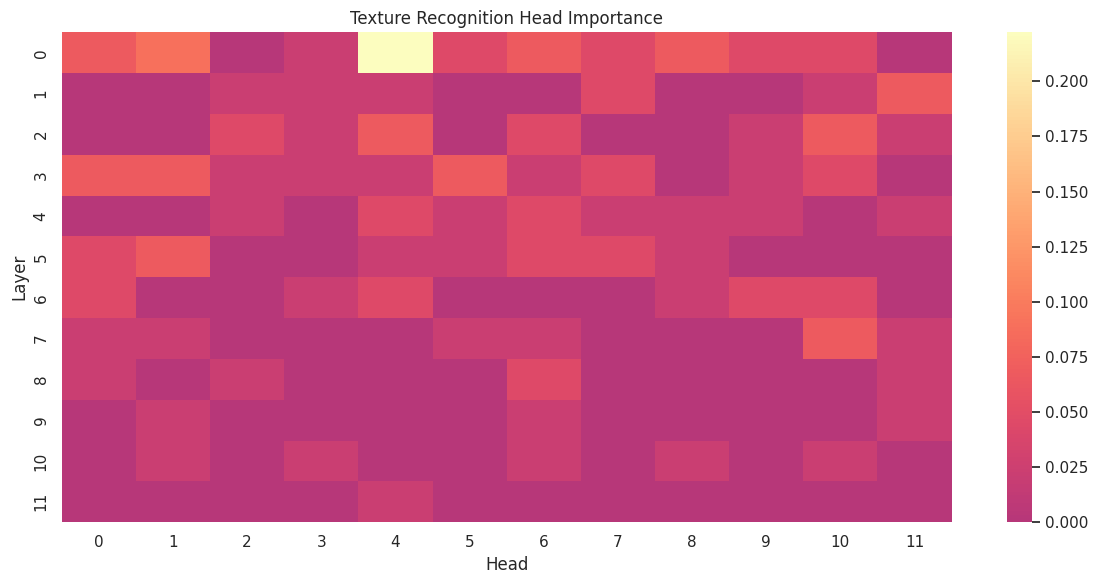

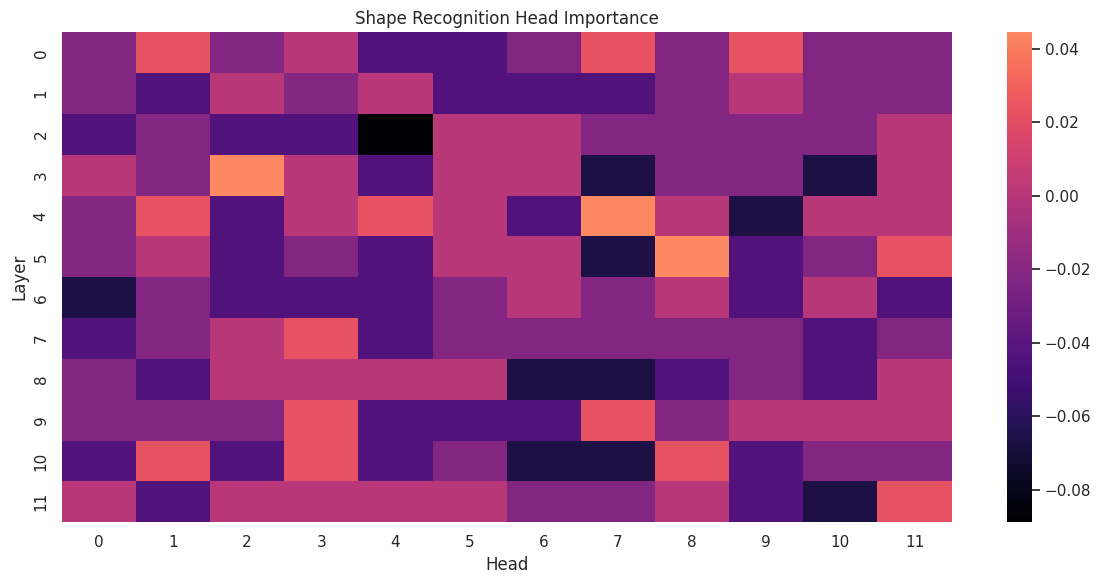

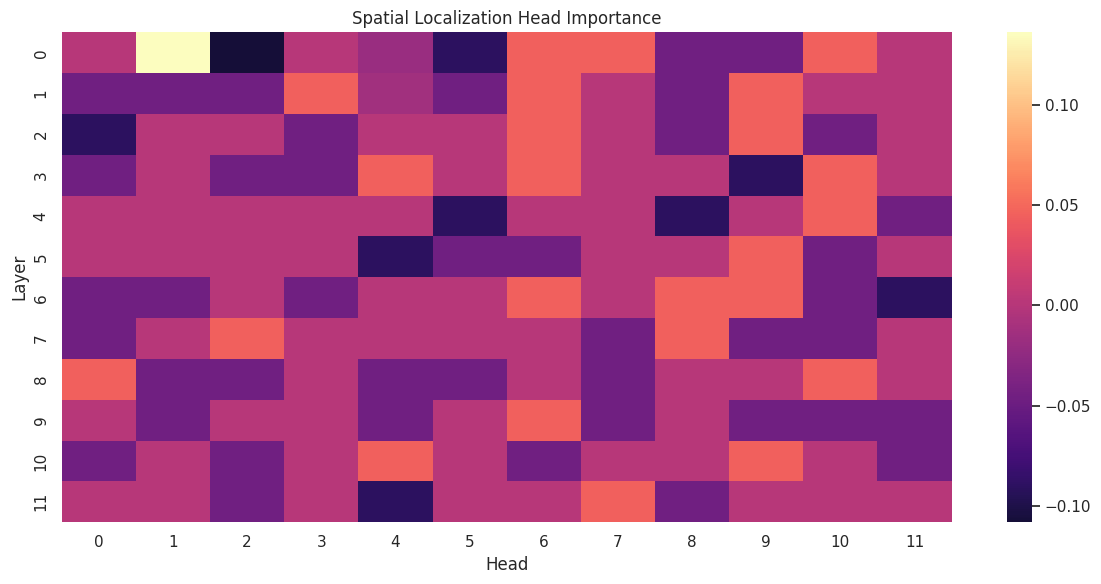

,layer,head,clean_acc_drop,texture_acc_drop,shape_acc_drop,spatial_drop,clean_macro_f1_drop,texture_macro_f1_drop,shape_macro_f1_drop,baseline_clean_acc,baseline_texture_acc,baseline_shape_acc,baseline_spatial_alignment,texture_rank,shape_rank,spatial_rank
4,0,4,0.022222,0.222222,-0.044444,-0.018939,0.028991,0.217648,-0.051975,0.911111,0.911111,0.355556,0.272727,1.0,99.0,93.0
1,0,1,0.000000,0.088889,0.022222,0.136364,0.000000,0.090079,0.022571,0.911111,0.911111,0.355556,0.272727,2.0,4.0,1.0
6,0,6,0.022222,0.066667,-0.022222,0.045455,0.021975,0.065110,-0.017856,0.911111,0.911111,0.355556,0.272727,3.0,55.0,2.0
0,0,0,0.000000,0.066667,-0.022222,0.000000,0.000000,0.065110,-0.017856,0.911111,0.911111,0.355556,0.272727,3.0,55.0,26.0
8,0,8,0.000000,0.066667,-0.022222,-0.045455,0.000000,0.068747,-0.015152,0.911111,0.911111,0.355556,0.272727,3.0,55.0,94.0
36,3,0,0.000000,0.066667,0.000000,-0.045455,0.000000,0.065110,0.006311,0.911111,0.911111,0.355556,0.272727,3.0,17.0,94.0
28,2,4,0.000000,0.066667,-0.088889,0.000000,0.000000,0.067264,-0.067434,0.911111,0.911111,0.355556,0.272727,3.0,144.0,26.0
23,1,11,0.000000,0.066667,-0.022222,0.000000,0.000000,0.068747,-0.017856,0.911111,0.911111,0.355556,0.272727,3.0,55.0,26.0
94,7,10,0.000000,0.066667,-0.044444,-0.045455,0.000000,0.068747,-0.035580,0.911111,0.911111,0.355556,0.272727,3.0,99.0,94.0
61,5,1,0.000000,0.066667,0.000000,0.000000,0.000000,0.068747,0.002557,0.911111,0.911111,0.355556,0.272727,3.0,17.0,26.0


,layer,head,clean_acc_drop,texture_acc_drop,shape_acc_drop,spatial_drop,clean_macro_f1_drop,texture_macro_f1_drop,shape_macro_f1_drop,baseline_clean_acc,baseline_texture_acc,baseline_shape_acc,baseline_spatial_alignment,texture_rank,shape_rank,spatial_rank
55,4,7,0.000000,0.022222,0.044444,0.000000,0.000000,0.022066,0.036401,0.911111,0.911111,0.355556,0.272727,33.0,1.0,26.0
68,5,8,0.000000,0.022222,0.044444,0.000000,0.000000,0.022770,0.038831,0.911111,0.911111,0.355556,0.272727,33.0,1.0,26.0
38,3,2,-0.022222,0.022222,0.044444,-0.045455,-0.021669,0.022770,0.038895,0.911111,0.911111,0.355556,0.272727,33.0,1.0,94.0
1,0,1,0.000000,0.088889,0.022222,0.136364,0.000000,0.090079,0.022571,0.911111,0.911111,0.355556,0.272727,2.0,4.0,1.0
128,10,8,-0.022222,0.022222,0.022222,0.000000,-0.021669,0.022770,0.018686,0.911111,0.911111,0.355556,0.272727,33.0,4.0,26.0
7,0,7,0.000000,0.044444,0.022222,0.045455,0.000000,0.045635,0.018061,0.911111,0.911111,0.355556,0.272727,14.0,4.0,2.0
9,0,9,0.000000,0.044444,0.022222,-0.045455,0.001245,0.045635,0.024857,0.911111,0.911111,0.355556,0.272727,14.0,4.0,94.0
121,10,1,0.000000,0.022222,0.022222,0.000000,0.000000,0.022770,0.018061,0.911111,0.911111,0.355556,0.272727,33.0,4.0,26.0
87,7,3,0.000000,0.000000,0.022222,0.000000,0.000000,0.000000,0.022571,0.911111,0.911111,0.355556,0.272727,74.0,4.0,26.0
111,9,3,0.000000,0.000000,0.022222,0.000000,0.000000,0.000000,0.018061,0.911111,0.911111,0.355556,0.272727,74.0,4.0,26.0


,layer,head,clean_acc_drop,texture_acc_drop,shape_acc_drop,spatial_drop,clean_macro_f1_drop,texture_macro_f1_drop,shape_macro_f1_drop,baseline_clean_acc,baseline_texture_acc,baseline_shape_acc,baseline_spatial_alignment,texture_rank,shape_rank,spatial_rank
1,0,1,0.000000,0.088889,0.022222,0.136364,0.000000,0.090079,0.022571,0.911111,0.911111,0.355556,0.272727,2.0,4.0,1.0
7,0,7,0.000000,0.044444,0.022222,0.045455,0.000000,0.045635,0.018061,0.911111,0.911111,0.355556,0.272727,14.0,4.0,2.0
6,0,6,0.022222,0.066667,-0.022222,0.045455,0.021975,0.065110,-0.017856,0.911111,0.911111,0.355556,0.272727,3.0,55.0,2.0
10,0,10,0.000000,0.044444,-0.022222,0.045455,0.000000,0.045635,-0.017856,0.911111,0.911111,0.355556,0.272727,14.0,55.0,2.0
15,1,3,0.000000,0.022222,-0.022222,0.045455,0.000000,0.024253,-0.015256,0.911111,0.911111,0.355556,0.272727,33.0,55.0,2.0
96,8,0,0.000000,0.022222,-0.022222,0.045455,0.000000,0.022066,-0.017856,0.911111,0.911111,0.355556,0.272727,33.0,55.0,2.0
78,6,6,0.000000,0.000000,0.000000,0.045455,0.000000,0.000000,0.000000,0.911111,0.911111,0.355556,0.272727,74.0,17.0,2.0
69,5,9,0.000000,0.000000,-0.044444,0.045455,0.000000,0.000000,-0.035580,0.911111,0.911111,0.355556,0.272727,74.0,99.0,2.0
58,4,10,-0.022222,0.000000,0.000000,0.045455,-0.021669,0.000000,0.002557,0.911111,0.911111,0.355556,0.272727,74.0,17.0,2.0
46,3,10,0.000000,0.044444,-0.066667,0.045455,0.000000,0.045635,-0.053249,0.911111,0.911111,0.355556,0.272727,14.0,134.0,2.0


,probe,layer,head,drop
0,texture,0,4,0.222222
1,shape,4,7,0.044444
2,spatial,0,1,0.136364


Texture-critical examples table


,path,label,base_true_prob,ablated_true_prob,prob_drop
0,data/data/high_new1/1752_2.jpg,2,0.949518,0.067324,0.882195
1,data/data/high_new1/1769_2.jpg,2,0.998877,0.122776,0.876102
2,data/data/high_new1/1461_2.jpg,2,0.990776,0.122144,0.868632
3,data/data/high_new1/1903_2.png,2,0.961094,0.187747,0.773346


... (4 outputs left out)

Baseline metrics summary


,value
training_time_sec,408.69
clean_accuracy,0.950877
clean_macro_f1,0.949566
texture_accuracy,0.926316
texture_macro_f1,0.928442
shape_accuracy,0.445614
shape_macro_f1,0.339063
spatial_alignment,0.458333
probe_baseline,"{'clean_acc': 0.9111111111111111, 'texture_acc..."


Interpretation summary
Interpretation summary:
Most texture-critical head: layer 0, head 4, accuracy drop=0.2222
Most shape-critical head: layer 4, head 7, accuracy drop=0.0444
Most spatial-critical head: layer 0, head 1, spatial drop=0.1364
Baseline clean / texture / shape accuracy: 0.9509 / 0.9263 / 0.4456
Baseline spatial alignment: 0.4583
Spatial top-head ablation changed localization score from 0.2727 to 0.1364


{'history_df':    epoch  train_loss  train_acc  train_macro_f1  val_loss   val_acc  \
 0      1    0.413561   0.851351        0.843877  0.243750  0.915789   
 1      2    0.077852   0.980480        0.979603  0.176447  0.926316   
 2      3    0.016450   0.999249        0.999051  0.174184  0.926316   
 3      4    0.004571   1.000000        1.000000  0.192050  0.933333   
 4      5    0.002622   1.000000        1.000000  0.205804  0.933333   
 
    val_macro_f1  
 0      0.912016  
 1      0.924418  
 2      0.922210  
 3      0.929640  
 4      0.929640  ,
 'baseline_summary':                 view  accuracy  macro_f1
 0              clean  0.950877  0.949566
 1            texture  0.926316  0.928442
 2              shape  0.445614  0.339063
 3  spatial_alignment  0.458333       NaN,
 'clean_report_df':               precision    recall  f1-score     support
 low            0.976744  0.954545  0.965517  132.000000
 medium         0.901099  0.942529  0.921348   87.000000
 high           

In [95]:
base_dataset, folder_remap, labels, idx_train, idx_val, idx_test, skipped_files = make_splits(DATA_ROOT)
print('Dataset folders:', base_dataset.class_to_idx)
print('Train / Val / Test:', len(idx_train), len(idx_val), len(idx_test))
print('Skipped unreadable files:', {split: len(paths) for split, paths in skipped_files.items()})

model, processor = build_model(num_labels=len(CLASS_NAMES))
ablator = ViTHeadAblator(model)

train_loader = make_loader(base_dataset, idx_train, processor, folder_remap, view='clean', shuffle=True)
val_loader = make_loader(base_dataset, idx_val, processor, folder_remap, view='clean', shuffle=False)
test_clean_loader = make_loader(base_dataset, idx_test, processor, folder_remap, view='clean', shuffle=False)
test_texture_loader = make_loader(base_dataset, idx_test, processor, folder_remap, view='texture', shuffle=False)
test_shape_loader = make_loader(base_dataset, idx_test, processor, folder_remap, view='shape', shuffle=False)

start_time = time.time()
history_df, criterion = fit_model(model, train_loader, val_loader, idx_train, labels)
training_time = time.time() - start_time
plot_training_history(history_df)
display(history_df.round(4))

clean_metrics = evaluate_loader(model, test_clean_loader, criterion=criterion)
texture_metrics = evaluate_loader(model, test_texture_loader, criterion=criterion)
shape_metrics = evaluate_loader(model, test_shape_loader, criterion=criterion)
spatial_dataset = CrowdVitDataset(base_dataset, idx_test, processor, folder_remap, view='clean')
spatial_alignment, spatial_details = quadrant_localization_score(model, spatial_dataset)

baseline_summary = pd.DataFrame([
    {'view': 'clean', 'accuracy': clean_metrics['acc'], 'macro_f1': clean_metrics['macro_f1']},
    {'view': 'texture', 'accuracy': texture_metrics['acc'], 'macro_f1': texture_metrics['macro_f1']},
    {'view': 'shape', 'accuracy': shape_metrics['acc'], 'macro_f1': shape_metrics['macro_f1']},
    {'view': 'spatial_alignment', 'accuracy': spatial_alignment, 'macro_f1': np.nan},
])
display(baseline_summary)
plot_confusion(clean_metrics['labels'], clean_metrics['preds'], title='Clean Test Confusion Matrix')

clean_report_df = pd.DataFrame(clean_metrics['report']).T
texture_report_df = pd.DataFrame(texture_metrics['report']).T
shape_report_df = pd.DataFrame(shape_metrics['report']).T
print('Clean-view classification report')
display(clean_report_df.round(4))
print('Texture-probe classification report')
display(texture_report_df.round(4))
print('Shape-probe classification report')
display(shape_report_df.round(4))
print('Spatial localization details')
display(spatial_details.head(10))

probe_indices = balanced_subset_indices(idx_test, labels, per_class=HEAD_SCAN_PER_CLASS)
probe_loaders = {
    'clean': make_loader(base_dataset, probe_indices, processor, folder_remap, view='clean', shuffle=False),
    'texture': make_loader(base_dataset, probe_indices, processor, folder_remap, view='texture', shuffle=False),
    'shape': make_loader(base_dataset, probe_indices, processor, folder_remap, view='shape', shuffle=False),
}
probe_localization_dataset = CrowdVitDataset(base_dataset, probe_indices, processor, folder_remap, view='clean')

head_df, probe_baseline = run_head_ablation_sweep(model, ablator, probe_loaders, probe_localization_dataset)
head_df['texture_rank'] = head_df['texture_acc_drop'].rank(ascending=False, method='min')
head_df['shape_rank'] = head_df['shape_acc_drop'].rank(ascending=False, method='min')
head_df['spatial_rank'] = head_df['spatial_drop'].rank(ascending=False, method='min')

texture_heatmap = plot_head_heatmap(head_df, 'texture_acc_drop', 'Texture Recognition Head Importance')
shape_heatmap = plot_head_heatmap(head_df, 'shape_acc_drop', 'Shape Recognition Head Importance')
spatial_heatmap = plot_head_heatmap(head_df, 'spatial_drop', 'Spatial Localization Head Importance')
display(head_df.sort_values('texture_acc_drop', ascending=False).head(10))
display(head_df.sort_values('shape_acc_drop', ascending=False).head(10))
display(head_df.sort_values('spatial_drop', ascending=False).head(10))

top_texture = head_df.sort_values('texture_acc_drop', ascending=False).iloc[0]
top_shape = head_df.sort_values('shape_acc_drop', ascending=False).iloc[0]
top_spatial = head_df.sort_values('spatial_drop', ascending=False).iloc[0]

top_heads = pd.DataFrame([
    {'probe': 'texture', 'layer': int(top_texture['layer']), 'head': int(top_texture['head']), 'drop': float(top_texture['texture_acc_drop'])},
    {'probe': 'shape', 'layer': int(top_shape['layer']), 'head': int(top_shape['head']), 'drop': float(top_shape['shape_acc_drop'])},
    {'probe': 'spatial', 'layer': int(top_spatial['layer']), 'head': int(top_spatial['head']), 'drop': float(top_spatial['spatial_drop'])},
])
display(top_heads)

texture_probe_dataset = CrowdVitDataset(base_dataset, probe_indices, processor, folder_remap, view='texture')
shape_probe_dataset = CrowdVitDataset(base_dataset, probe_indices, processor, folder_remap, view='shape')
clean_probe_dataset = CrowdVitDataset(base_dataset, probe_indices, processor, folder_remap, view='clean')

texture_examples = collect_probability_drop_examples(
    model, ablator, texture_probe_dataset, int(top_texture['layer']), int(top_texture['head'])
)
shape_examples = collect_probability_drop_examples(
    model, ablator, shape_probe_dataset, int(top_shape['layer']), int(top_shape['head'])
)
spatial_examples, base_spatial_score, ablated_spatial_score = collect_spatial_examples(
    model, ablator, clean_probe_dataset, int(top_spatial['layer']), int(top_spatial['head'])
)

print('Texture-critical examples table')
display(texture_examples)
print('Shape-critical examples table')
display(shape_examples)
print('Spatial-critical examples table')
display(spatial_examples)

show_image_examples(texture_examples, title='Texture-critical head examples', view='texture')
show_image_examples(shape_examples, title='Shape-critical head examples', view='shape')
show_image_examples(spatial_examples, title='Spatial-critical head examples', view='clean')

baseline_summary_dict = {
    'training_time_sec': round(training_time, 2),
    'clean_accuracy': clean_metrics['acc'],
    'clean_macro_f1': clean_metrics['macro_f1'],
    'texture_accuracy': texture_metrics['acc'],
    'texture_macro_f1': texture_metrics['macro_f1'],
    'shape_accuracy': shape_metrics['acc'],
    'shape_macro_f1': shape_metrics['macro_f1'],
    'spatial_alignment': spatial_alignment,
    'probe_baseline': {
        'clean_acc': probe_baseline['clean_acc'],
        'texture_acc': probe_baseline['texture_acc'],
        'shape_acc': probe_baseline['shape_acc'],
        'spatial_alignment': probe_baseline['spatial_alignment'],
    },
}


recommendation_lines = [
    'Interpretation summary:',
    f"Most texture-critical head: layer {int(top_texture['layer'])}, head {int(top_texture['head'])}, accuracy drop={top_texture['texture_acc_drop']:.4f}",
    f"Most shape-critical head: layer {int(top_shape['layer'])}, head {int(top_shape['head'])}, accuracy drop={top_shape['shape_acc_drop']:.4f}",
    f"Most spatial-critical head: layer {int(top_spatial['layer'])}, head {int(top_spatial['head'])}, spatial drop={top_spatial['spatial_drop']:.4f}",
    f"Baseline clean / texture / shape accuracy: {clean_metrics['acc']:.4f} / {texture_metrics['acc']:.4f} / {shape_metrics['acc']:.4f}",
    f"Baseline spatial alignment: {spatial_alignment:.4f}",
    f"Spatial top-head ablation changed localization score from {base_spatial_score:.4f} to {ablated_spatial_score:.4f}",
]

print('Baseline metrics summary')
display(pd.DataFrame([baseline_summary_dict]).T.rename(columns={0: 'value'}))
print('Interpretation summary')
for line in recommendation_lines:
    print(line)

experiment_outputs = {
    'history_df': history_df,
    'baseline_summary': baseline_summary,
    'clean_report_df': clean_report_df,
    'texture_report_df': texture_report_df,
    'shape_report_df': shape_report_df,
    'spatial_details': spatial_details,
    'head_importance_df': head_df,
    'top_heads': top_heads,
    'texture_examples': texture_examples,
    'shape_examples': shape_examples,
    'spatial_examples': spatial_examples,
    'texture_heatmap': texture_heatmap,
    'shape_heatmap': shape_heatmap,
    'spatial_heatmap': spatial_heatmap,
    'baseline_summary_dict': baseline_summary_dict,
    'recommendation_lines': recommendation_lines,
}
experiment_outputs
